In [1]:
import pandas as pd
import glob
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import Perceptron
import matplotlib.pyplot as plt


# Read all CSV files from the specified directory


In [2]:
!gdown --id "1HKbsFuVsVl2Mh-OxPq01Sy66IxIPZLam"
!gdown --id "1zE_E-UmQWys1g41BHBv3GMNI2dTYcwwZ"
!gdown --id "1OdcSN79x9KPOsVL6pm161B5Sv8x95nXj"
!gdown --id "1kF8aolOLlo2b0KsAjiLNxv0OqAJB7BZA"
!gdown --id "1Mu_n3Htu-UvFmyorh9Z6OBbL1eXlPGLL"
!gdown --id "1Hw1Mp_yhgiLaxArxFD_pWDwyy2m53RNC"
!gdown --id "1a3WJHcD_NbhkJypNfdtGPSLmKIaU4XYE"

/usr/local/lib/python3.10/dist-packages/gdown/__main__.py:132: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1HKbsFuVsVl2Mh-OxPq01Sy66IxIPZLam
To: /content/actors.csv
100% 1.14M/1.14M [00:00<00:00, 101MB/s]
/usr/local/lib/python3.10/dist-packages/gdown/__main__.py:132: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1zE_E-UmQWys1g41BHBv3GMNI2dTYcwwZ
To: /content/directors.csv
100% 23.5k/23.5k [00:00<00:00, 34.9MB/s]
/usr/local/lib/python3.10/dist-packages/gdown/__main__.py:132: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://driv

# Initialize empty lists to store the data


In [3]:
actors = pd.read_csv('actors.csv')
directors = pd.read_csv('directors.csv')
movies = pd.read_csv('movies.csv')
movies2actors = pd.read_csv('movies2actors.csv')
movies2directors = pd.read_csv('movies2directors.csv')
ratings = pd.read_csv('u2base.csv')


In [4]:
top_10_actors = movies2actors['actorid'].value_counts().nlargest(10)
top_10_directors = movies2directors['directorid'].value_counts().nlargest(10)
top_10_actors_movies = movies[movies2actors['actorid'].isin(top_10_actors.index)]
top_10_directors_movies = movies[movies2directors['directorid'].isin(top_10_directors.index)]
print("Top 10 actors who have worked in the most movies:")
print(top_10_actors)
print("\nTop 10 directors who have worked in the most movies:")
print(top_10_directors)
print("\nMovies of the top 10 actors:")
print(top_10_actors_movies)
print("\nMovies of the top 10 directors:")
print(top_10_directors_movies)

Top 10 actors who have worked in the most movies:
actorid
1694741    51
745232     36
375938     33
2092485    31
1676554    31
809720     29
667623     29
438256     27
1672251    27
1513698    27
Name: count, dtype: int64

Top 10 directors who have worked in the most movies:
directorid
118604    52
5185      20
156165    14
260322    14
70986     13
263287    13
158572    13
121794    12
5798      12
148294    12
Name: count, dtype: int64

Movies of the top 10 actors:
      movieid  year isEnglish country  runningtime
15    1677631     3         T     USA            3
897   1898372     3         T     USA            3
2065  2208474     4         T     USA            1
2630  2361784     3         T     USA            2

Movies of the top 10 directors:
      movieid  year isEnglish country  runningtime
26    1682692     4         T     USA            2
30    1684430     4         T     USA            3
94    1697674     4         T     USA            2
210   1727885     4         T    

<ipython-input-4-7884a5f01646>:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  top_10_actors_movies = movies[movies2actors['actorid'].isin(top_10_actors.index)]
<ipython-input-4-7884a5f01646>:4: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  top_10_directors_movies = movies[movies2directors['directorid'].isin(top_10_directors.index)]


# Merge the datasets


In [5]:
movies = pd.merge(movies, movies2actors, on='movieid', how='left')
movies = pd.merge(movies, movies2directors, on='movieid', how='left')
movies = pd.merge(movies, ratings, on='movieid', how='left')

# Drop the rows with missing values


In [6]:
movies.dropna(inplace=True)


# Create a dataset for regression and classification



In [7]:
X = movies[['actorid', 'directorid']]
y = movies['rating']

# Create a linear regression model


In [8]:
linear_regression = LinearRegression()


# Create a decision tree regression model


In [9]:
decision_tree_regression = DecisionTreeRegressor()


# Perform cross-validation for the linear regression model


In [10]:
linear_regression_scores = cross_val_score(linear_regression, X, y, cv=5)


# Perform cross-validation for the decision tree regression model


In [11]:
decision_tree_regression_scores = cross_val_score(decision_tree_regression, X, y, cv=5)

# Convert the rating column into categorical variables


In [12]:
movies['rating_class'] = pd.cut(movies['rating'], bins=[0, 2, 4, 5], labels=[1, 2, 3])

# Create a perceptron model


In [13]:
perceptron = Perceptron()

# Perform cross-validation for the perceptron model


In [14]:
perceptron_scores = cross_val_score(perceptron, X, y, cv=5)

# Print the results for the linear regression model


In [15]:
print("Linear Regression Model Scores:")
print(linear_regression_scores)
print("Mean:", linear_regression_scores.mean())
print("Standard Deviation:", linear_regression_scores.std())

Linear Regression Model Scores:
[-0.00095365 -0.00027727 -0.00155023  0.0004984  -0.00412665]
Mean: -0.0012818796552219736
Standard Deviation: 0.0015780417800875064


# Print the results for the decision tree regression model


In [16]:
print("Decision Tree Regression Model Scores:")
print(decision_tree_regression_scores)
print("Mean:", decision_tree_regression_scores.mean())
print("Standard Deviation:", decision_tree_regression_scores.std())

Decision Tree Regression Model Scores:
[-0.32419271 -0.17610883 -0.15310743 -0.15682515 -0.26234991]
Mean: -0.21451680816913185
Standard Deviation: 0.06766301701858785


# Print the results for the perceptron model


In [17]:
print("Perceptron Model Scores:")
print(perceptron_scores)
print("Mean:", perceptron_scores.mean())
print("Standard Deviation:", perceptron_scores.std())

Perceptron Model Scores:
[0.15249979 0.22316787 0.10855411 0.22319975 0.20565566]
Mean: 0.18261543633915844
Standard Deviation: 0.045198385412756996


#  Plot the results


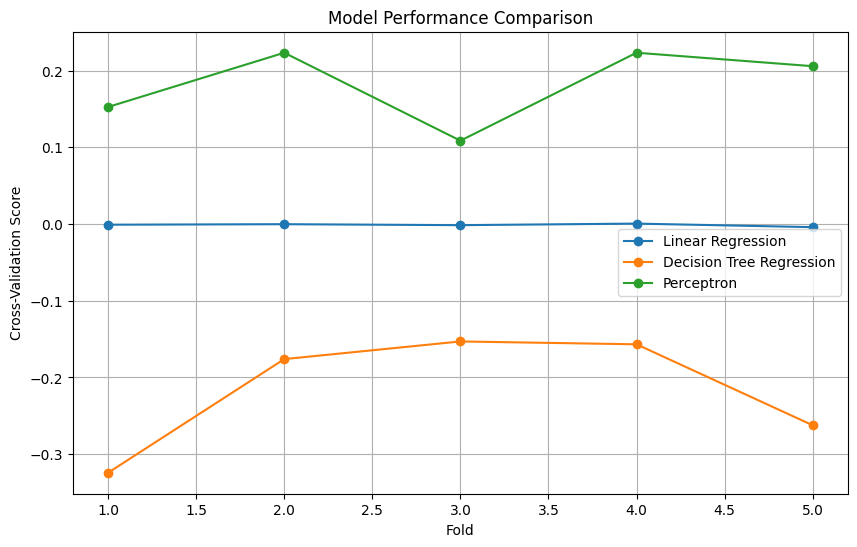

In [18]:
models = ['Linear Regression', 'Decision Tree Regression', 'Perceptron']
scores = [linear_regression_scores, decision_tree_regression_scores, perceptron_scores]
plt.figure(figsize=(10, 6))
for model, score in zip(models, scores):
    plt.plot(range(1, 6), score, marker='o', label=model)
plt.xlabel('Fold')
plt.ylabel('Cross-Validation Score')
plt.title('Model Performance Comparison')
plt.legend()
plt.grid(True)
plt.show()

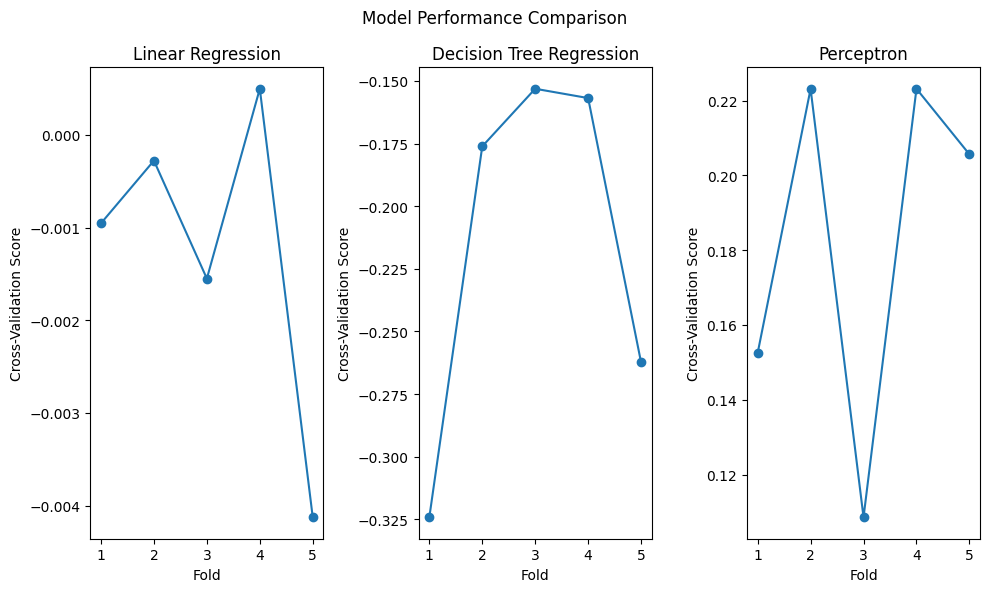

In [19]:

plt.figure(figsize=(10, 6))
plt.subplot(1, 3, 1)
plt.plot(range(1, 6), linear_regression_scores, marker='o')
plt.title('Linear Regression')
plt.xlabel('Fold')
plt.ylabel('Cross-Validation Score')

plt.subplot(1, 3, 2)
plt.plot(range(1, 6), decision_tree_regression_scores, marker='o')
plt.title('Decision Tree Regression')
plt.xlabel('Fold')
plt.ylabel('Cross-Validation Score')

plt.subplot(1, 3, 3)
plt.plot(range(1, 6), perceptron_scores, marker='o')
plt.title('Perceptron')
plt.xlabel('Fold')
plt.ylabel('Cross-Validation Score')

plt.suptitle('Model Performance Comparison')
plt.tight_layout()
plt.show()